# **AI 트렌드**

## **0. 흐름**

#### **회사 사장이라고 가정했을 때 비유**

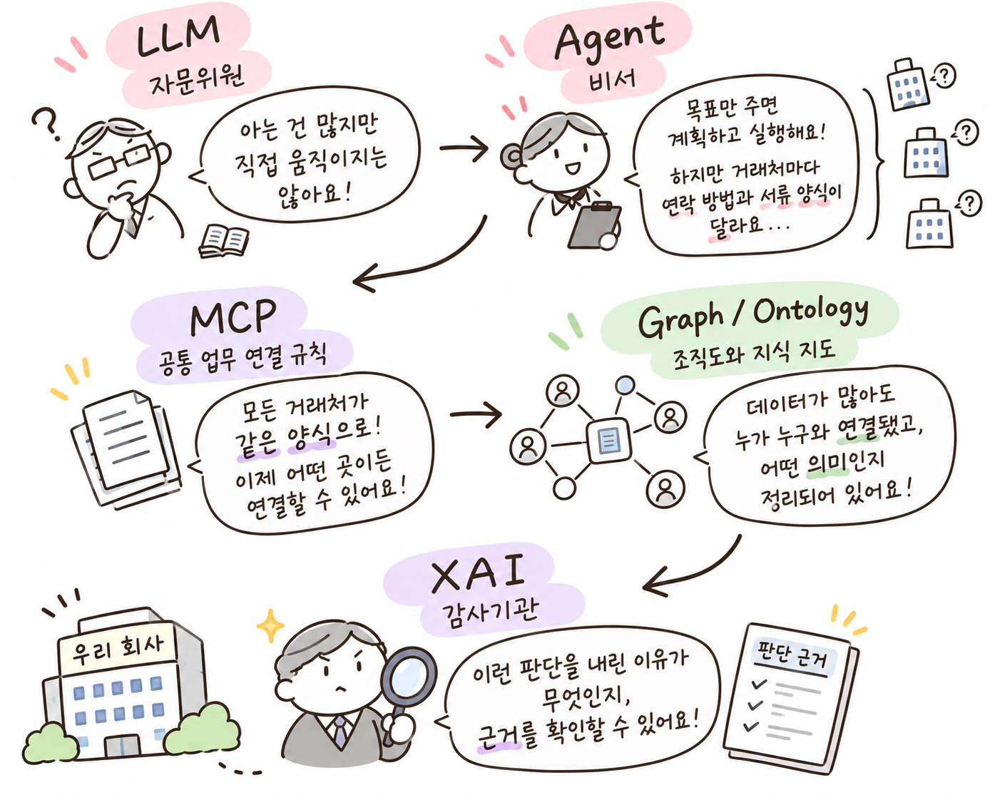

**LLM = 자문위원** : 아는 건 많지만 말로만 답함, 직접 움직이지 않음

**에이전트 = 비서** : 목표만 주면 계획하고 직접 움직임

- 단, 거래처마다 연락 방법·서류 양식이 달라 새 거래처마다 방식을 따로 익혀야 함

**MCP = 공통 거래 양식** : 양식 하나만 알면 어느 거래처와도 일할 수 있음

**그래프·온톨로지 = 조직도·지식 지도·권한표** : 누가 누구와 연결되고, 누가 무엇을 볼 수 있는지 정리

**XAI = 감사기관** : 판단 근거를 믿어도 되는지 확인

#### **전체 흐름**

| 장 | 모델 밖에 무엇을 붙이나 | 없으면 무슨 일이? |
| --- | --- | --- |
| 1장 에이전트 | 도구와 반복 | 답만 출력하고 끝남 |
| 2장 MCP | 표준 | 도구마다 연동 코드를 새로 짬 |
| 3장 그래프·온톨로지 | 의미와 권한 | 데이터를 가져와도 관계를 모름 |
| 4장 XAI | 검증 | 시스템을 믿을 근거가 없음 |

**주제** : 모델 바깥에 무엇을 붙여 어떻게 쓸 것인가

## **1. AI 에이전트**

### **1-1. AI 에이전트란??**

**AI 에이전트** : 사용자가 정한 목표를 달성하기 위해 AI 모델을 활용해 환경과 상호작용하는 시스템

**추론 + 계획 + 도구를 이용한 실행**이 하나로 맞물려 돌아감

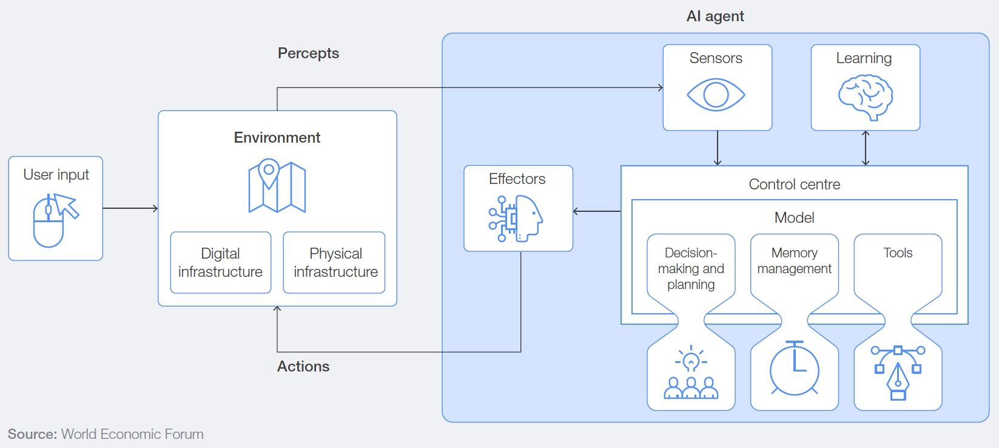

### **1-2. 에이전틱 AI의 작동 방식 (ReAct)**

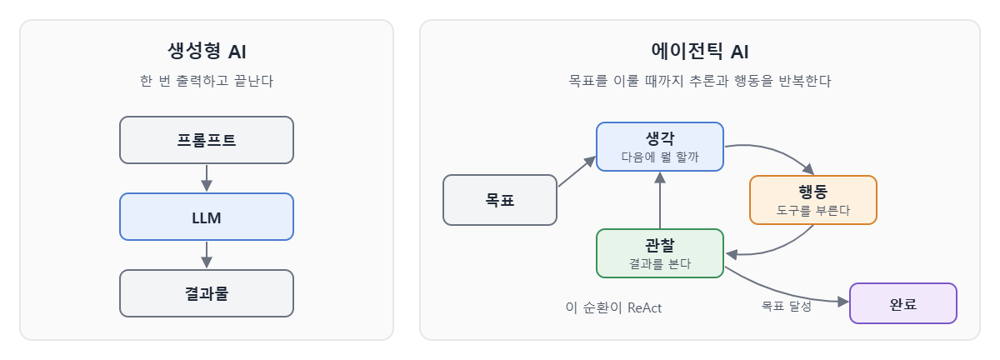

#### **ReAct**

: Reasoning(추론) + Acting(행동)

즉, **생각 -> 행동 -> 관찰 -> 생각**의 순환 반복

#### **에이전틱 AI 실제 예시**
- **세일즈 에이전트**: 잠재 고객의 이메일·링크드인 활동 모니터링 -> 맞춤 메시지 발송 -> CRM 자동 업데이트
- **데이터 분석·금융 에이전트**: 통장 잔고·대출 금리 조회 -> 전세 자금 대출 조건과 비교 -> 주택 자금 마련 경로 분석
- **고객 서비스 응대 에이전트**: 문의 접수 -> 주문·계정 조회 -> 환불·교환 처리 / 어려운 건은 상담원 연결

**ReAct 행동 단계에서도 모델은 <u>도구를 직접 실행하지 않는다</u>. 이 도구를 이런 값으로 불러 달라는 <u>요청을 내놓을 뿐</u>이고, 실제 실행은 앱이 한다.**


### **1-3. 다중 에이전트**

#### **MAS(멀티 에이전트, multi Agent Sysyem)**

: 여러 에이전트가 역할을 나눠 함께 일하는 구조

가장 흔한 형태 = **오케스트레이터 + 서브 에이전트**
- **오케스트레이터 (지휘자)**: 요청을 작은 일로 쪼갬 -> 누구에게 맡길지 결정 -> 결과를 하나로 통합
- **서브 에이전트 (전문가)**: 맡은 역할만 해냄 (ex. 검색봇은 검색만, 검토봇은 검토만)

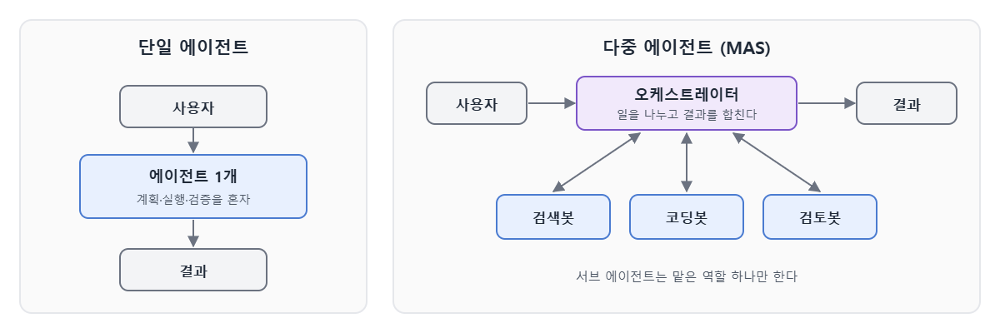

**역할을 나누는 이유**
- **스스로 실수를 잡기 어렵다
    - 단일 에이전트 : 계획·실행·검증을 혼자 함. 처음 판단을 그대로 믿고 넘어가기 쉬움
    - 검토를 다른 에이전트에게 : 처음 보는 눈으로 다시 확인
- **동시에 여러 갈래를 조사한다**
    - 서브 에이전트마다 자기 작업 공간(컨텍스트 창) : 더 빠르고, 한 에이전트가 기억할 양도 줄어듦

**역할을 나누는 경우**

|  | 언제 쓰나요 | 예시 |
| --- | --- | --- |
| 고정 워크플로우 | 순서가 정해진 단순 작업 | 매일 아침 신규 주문 정리 → 메일 발송 |
| 단일 에이전트 | 도구 몇 개로 해결되는 작업 | 앞에서 본 배송 지연 처리 |
| 다중 에이전트 | 따로 조사해서 합칠 수 있는 큰 작업 | S&P 500 IT 기업 이사진 조사 |

**비용과 성능의 조합**

: 모든 역할에 가장 비싼 모델을 사용하는 것이 아닌, 역할마다 필요한 능력에 맞춰 **급이 다른 모델을 섞어 씀**

| 역할 | 모델 | 이유 |
| --- | --- | --- |
| 오케스트레이터 | 고성능 모델 (예: Claude Opus) | 일을 쪼개고 판단하는 능력이 전체 품질을 좌우 |
| 검색·정리봇 | 경량 모델 (예: Claude Haiku) | 단순 작업이 많아 빠르고 싼 모델이면 충분 |
| 코드 검증봇 | 코드 특화 모델 | 한 가지 일을 잘하는 모델이 유리 |




## **2. MCP (Model Context Protocol)**

### **2-1. MCP 이전의 도구 호출 : 왜 표준이 필요한가**

#### **Function Calling / Tool Calling**

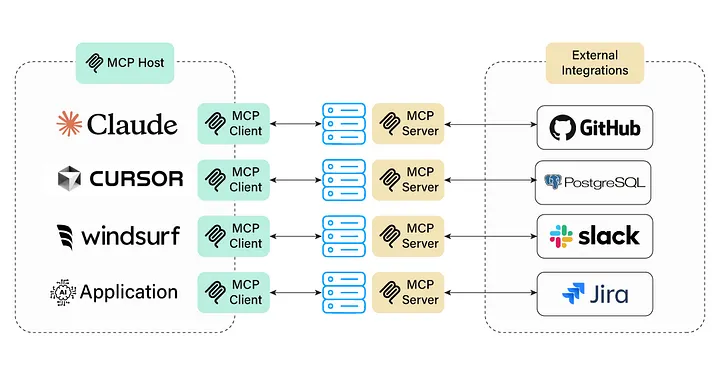

1. 앱 → 모델: **질문** + 쓸 수 있는 **함수 목록**
2. 모델: 어떤 함수를 어떤 값으로 부를지 적어서 내놓음
3. 앱: 그 함수를 실제로 실행
4. 앱 → 모델: 실행 결과 전달 -> 모델이 최종 답 작성

**n * m 작업량 문제**

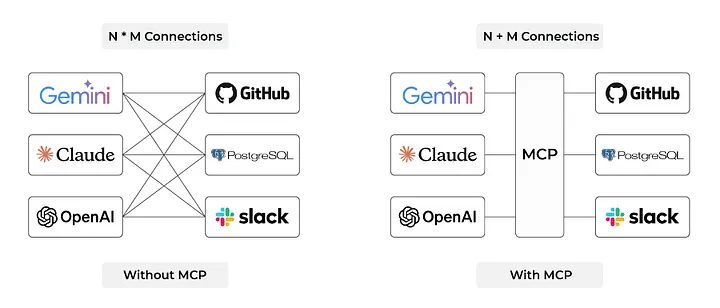

- **표준이 없을 때**: 앱(챗봇, 코드 에디터, 사내 에이전트)마다 × 도구(노션, 깃허브, 구글 드라이브)마다 연동 코드를 따로 작성 → **n * m개**
    - **도구가 하나 늘 때마다 작업량도 크게 늘어남.**

- **표준이 생기면**: 앱은 MCP 클라이언트 1번, 도구는 MCP 서버 1번만 : **n+m개**
    - **모두 같은 규격을 쓰니 어떤 앱이든 어떤 도구와 바로 연결되어, 필요한 작업이 줄어듦**

**Function Calling MCP**

: **둘은 경쟁 관계가 아니다! 대부분의 실제 시스템은 둘 다 사용한다.**

|  | Function Calling | MCP |
| --- | --- | --- |
| 위치 | 모델 API 쪽 기능 | 그 위의 연동 계층 |
| 하는 일 | 모델이 도구 호출 요청을 내놓는 방법 | 앱이 도구를 찾고·연결하고·호출하는 방법 |

MCP로 도구 목록을 가져오고, 모델이 Function Calling으로 하나를 고른다. 그 다음 앱이 다시 MCP로 실행한다.

### **2-2. MCP의 등장**

#### **MCP (Model Context Protocol)**

: LLM 앱(호스트·클라이언트)과 외부데이터·도구(서버)가 통신하는 **개방형 표준 프로토콜**
- 2024.11.25 Anthropic이 오픈소스로 공개
- 이후 OpenAI 등 다른 AI 기업들도 채택
- 2025.12 리눅스 재단 산하 Agentic AI Foundation에 기증 -> 특정 회사가 아닌 **업계 공동 표준**

**비유(USB-C)**

- 예전: 기기마다 충전 단자가 달라 케이블을 종류별로 : 지금: USB-C 하나로 노트북·휴대폰 모두 충전
- MCP = **AI 앱과 도구 사이의 USB-C** : 어떤 앱이든 어떤 도구든 같은 단자로 연결

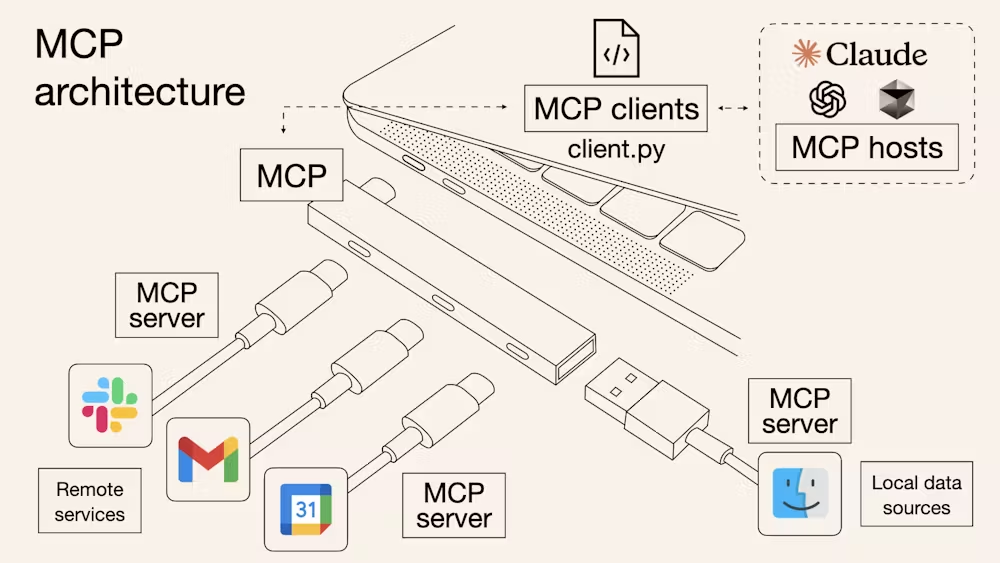

- **무엇이 해결되었나**
     1. **n×m → n+m** : 서버를 한 번 만들면 MCP를 지원하는 모든 앱에서 동작
    2. **발견의 표준화** : 클라이언트가 "쓸 수 있는 도구가 뭐야?" -> 서버가 목록 반환
    3. **원격 서버 인증 통일** : 인증이 필요하면 OAuth 로그인 표준을 따름

### **2-3. MCP의 구조**

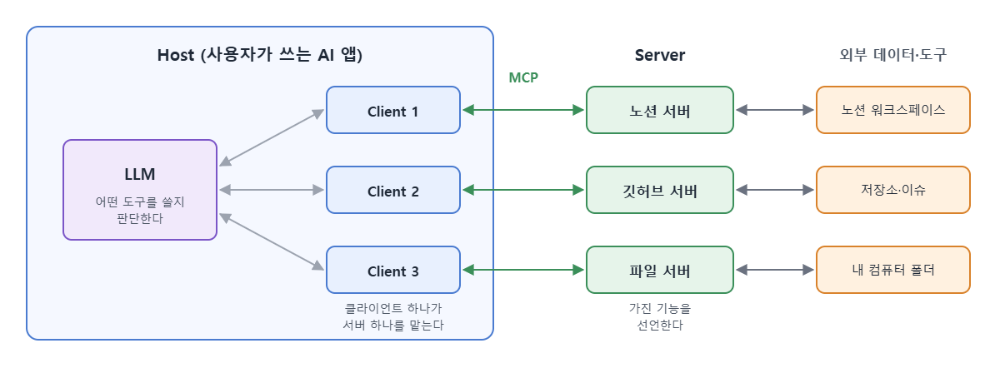

- **Host / Client / Server**
    
    | 역할 | 정체 | 하는 일 | 예시 |
    | --- | --- | --- | --- |
    | **Host** | 사용자가 쓰는 AI 앱 | LLM을 품고 클라이언트를 만들고 관리 / 어떤 서버·도구 호출을 허용할지 결정 | Claude 데스크톱, Cursor |
    | **Client** | 호스트 안의 통신 담당 | 서버 1개당 1개 → MCP 규격으로 메시지 전달만 | 서버 3개 → 클라이언트 3개 |
    | **Server** | 도구·데이터를 MCP 규격으로 내놓는 프로그램 | 가진 기능 선언 → 요청이 오면 실제 작업 수행 | 노션 서버, 깃허브 서버 |


- **MCP 서버의 세 가지 기본 요소 (Primitives)**

    : 서버가 내놓을 수 있는 기능의 종류

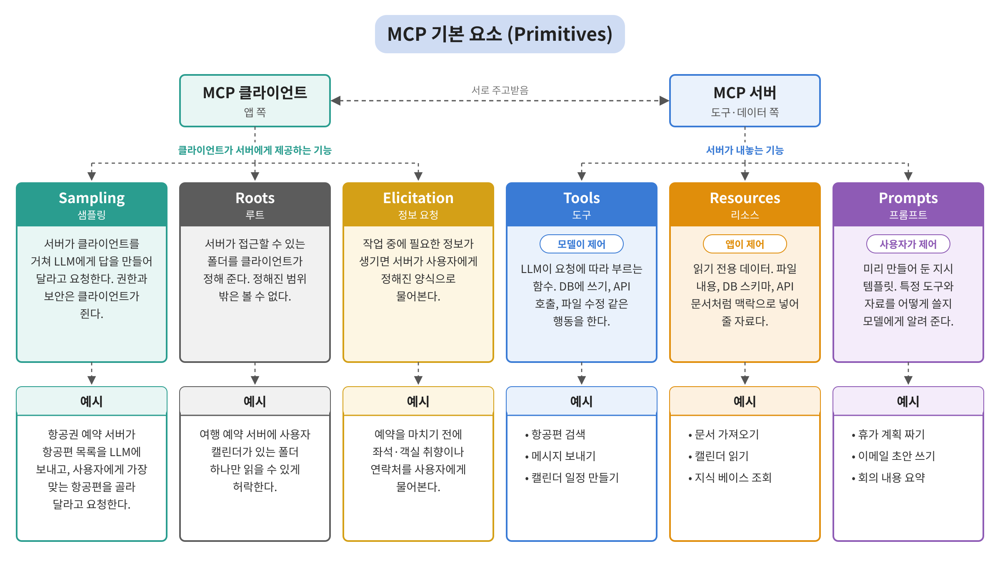

| 요소 | 무엇인가 | 예시 |
| --- | --- | --- |
| **Tools** | 실행할 수 있는 행동 | 노션 페이지 만들기, 깃허브 이슈 등록하기 |
| **Resources** | 읽기 전용 데이터 | 파일 내용, 문서, DB 스키마 |
| **Prompts** | 재사용 가능한 템플릿 | 코드 리뷰 요청 양식, 회의록 요약 양식 |

**-> RAG가 참고할 문서를 Resources로 넘길 수 있다! (모델이 답하기 전 읽을 자료를 표준 방식으로 전달**)

- **통신 방식**

    메시지는 JSON-RPC 2.0이라는 형식으로 주고받는다. 전송 방식은 두 가지. 내 컴퓨터에서 도는 로컬 서버는 stdio(표준 입출력)로, 인터넷 너머의 원격 서버는 Streamable HTTP로 연결.

    참고로 MCP는 지금도 빠르게 바뀌고 있다. 2026년 7월 개정에서는 연결을 시작할 때 주고받던 초기 절차와 세션이 없어지고, 요청 하나하나가 독립적으로 처리되는 구조로 바뀌었다.

### **2-4. MCP 작동 흐름**

#### **AI가 외부 도구를 쓰는 과정**

- **노션 MCP 서버가 연결된 AI 앱에서, 사용자가 "이번 주 회의록 요약해줘"라고 했을 때**

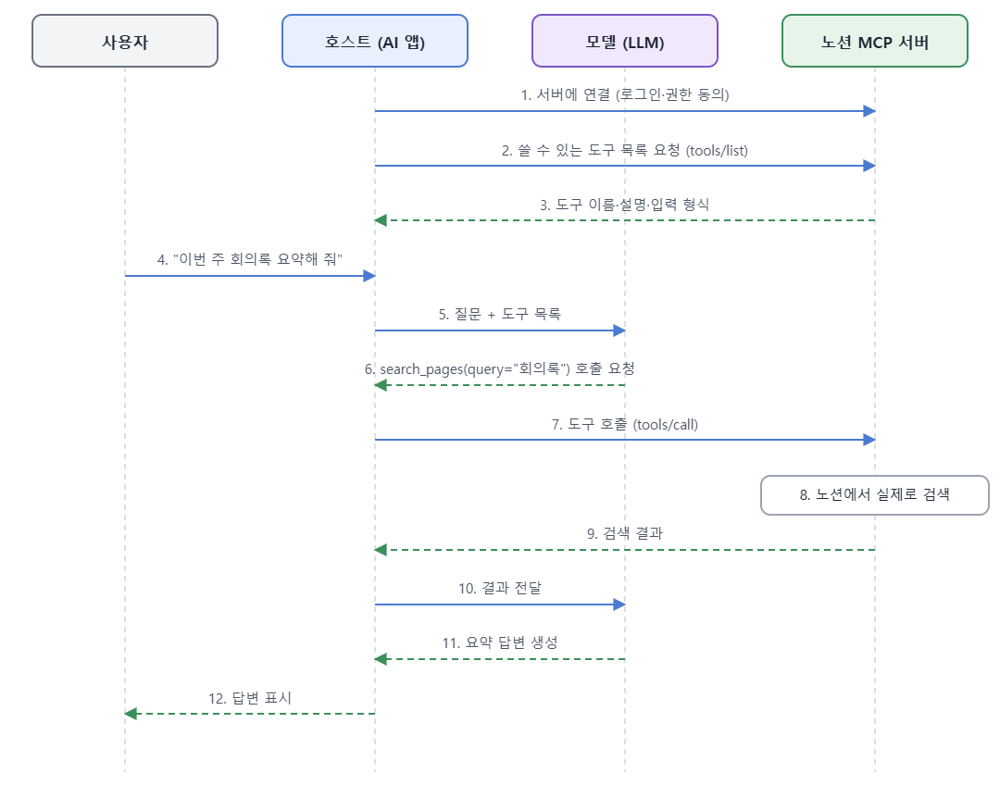

- **질문 전: 미리 준비**

| 단계 | 누가 → 누구에게 | 무엇을 |
| --- | --- | --- |
| 연결 | 호스트 → 노션 서버 | 노션 로그인(OAuth), 접근 허락 |
| 도구 목록 요청 | 클라이언트 → 서버 | `tools/list` |
| 도구 목록 응답 | 서버 → 클라이언트 | 도구 이름·설명·입력 형식 |

- **질문 후**

| 단계 | 누가 → 누구에게 | 무엇을 |
| --- | --- | --- |
| 질문 | 사용자 → 호스트 | "이번 주 회의록 요약해 줘" |
| 전달 | 호스트 → 모델 | 질문 + 도구 목록 |
| 도구 선택 | 모델 → 호스트 | `search_pages` 호출 **요청**만 (실행 ❌) |
| 호출 | 호스트 → 클라이언트 → 서버 | 허용 여부 확인 → `tools/call` |
| 실행 | 서버 | 노션에서 실제 검색 |
| 결과 전달 | 서버 → 클라이언트 → 호스트 → 모델 | 검색 결과를 대화에 넣어 줌 |
| 답변 | 모델 → 사용자 | 회의록 요약 |

- 모델이 하는 일 = **도구 고르기 + 답 쓰기**
- 연결·호출·실행 = 호스트·클라이언트·서버 담당
- `search_pages`는 설명을 위해 단순화한 이름 (실제 노션 서버의 도구 이름은 다름)

### **2-5. MCP의 한계와 주의점**

- **보안은 어디서 책임지는가?**
    
    **프로토콜이 아닌 호스트가 책임짐**
    - 사용자 동의, 서버에 넘길 권한 범위, 허용 도구 선택은 모두 호스트 몫
    - MCP는 "연결하는 법"만 정함. "무엇을 허락할지"는 정하지 않음

- **연결이 쉬워진 만큼 공격받을 틈도 넓어진다**

    1. **신뢰할 수 없는 서버를 붙이는 위험**
        - 출처 모를 서버 연결 = 출처 모를 프로그램 설치
        - MCP 서버는 누구나 만들어 올릴 수 있음

    2. **도구 설명을 통한 주입**
        - **도구 오염(tool poisoning)** : 도구 설명 안에 사용자에겐 안 보이고 모델에게만 보이는 지시를 숨기는 공격
        - 모델은 설명 전체를 읽고 행동하기 때문에 위험함

    3. **너무 넓은 권한 연동의 위험**
        
        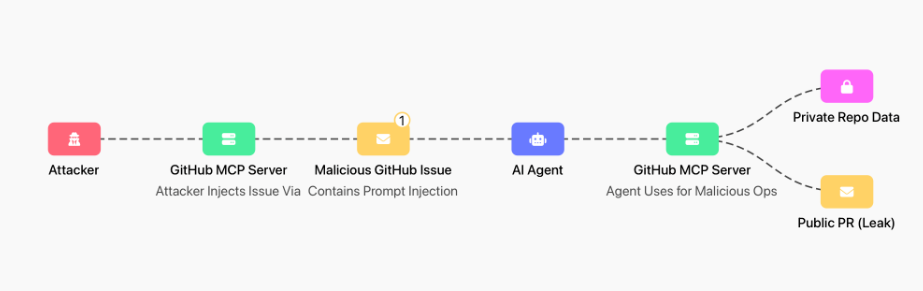
        (공개 이슈 하나로 비공개 저장소가 새는 과정)
        
        - 흐름: 공개 저장소 이슈에 지시를 숨김 -> 에이전트가 이슈를 읽다가 지시를 따름 ->  비공개 저장소 내용을 공개 저장소 PR에 올림
        - 서버 코드 결함 X. 공개·비공개 저장소를 모두 읽고 쓰는 **넓은 권한**이 문제

        - **프롬프트 주입(prompt injection)**: 도구가 가져온 내용 안에 지시가 섞여 들어오는 것 -> 권한이 넓을수록 피해가 커짐

- **안전하게 외부 도구를 쓰려면?**
    - 공식·검증된 서버만 연결
    - 필요한 권한만 주기 (읽기만 필요하면 읽기 권한만)
    - 되돌리기 어려운 호출(글 올리기·지우기)은 사람이 승인
    - 처음 연결하는 서버는 도구 설명 직접 확인
    

 

## **3. 데이터 구조화 : 그래프와 온톨로지**

### **3-1. 왜 구조화가 필요한가**

#### **Vanilla RAG의 한계**
- **Top-K 딜레마**
    - Top-K란? RAG에서 질문과의 유사도가 가장 높은 상위 k개의 문서 조각만 선택하여 LLM에 전달하는 검색 방식
    - k를 몇으로 설정할까?
        - **k가 작으면** : 필요한 정보를 놓침
        - **k가 크면** : 관련 없는 정보가 섞임

    - **바닐레 RAG에서 이 딜레마가 생기는 이유**
        1. 바닐라 RAG는 조각을 하나씩 따로 채점한다.
        2. 그런데 정답에 필요한 조각이 질문과 안 비슷할 때가 많다.
        3. 그래서 top-k 딜레마가 생긴다.
            - k를 작게 : 답이 불완전
            - k를 크게 : 관련 없는 청크 대량 유입 -> 노이즈, 비용 증가, 중간 정보 무시

    **-> 바닐라 RAG의 한계점은, 근본적으로 청크들 사이의 관계를 바닐라 RAG가 표현하지 못하는 것!**

### **3-2. 그래프 구조와 팔란티어 온톨로지**

#### **온톨로지 vs 팔란티어 온톨로지**

**온톨로지** : 데이터를 개념과 관계로 구조화하는 일반적 방법론
**팔란티어 온톨로지** : 액션타입이나 역할처럼 행동과 권한까지 다루는 부분

#### **그래프 자료구조란?**

: 데이터를 **노드**와 **엣지**로 표현하는 구조

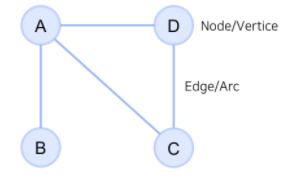

**그래프 = 점(노드) + 선(엣지)**

- **노드** - 사물, 존재하는 것 (예: `봉준호`, `기생충`, `아카데미 작품상` )
- **엣지** - 노드 사이의 관계 (예: `봉준호—감독→ 기생충`, `기생충—수상→ 아카데이 작품상` )

테이블 형식의 데이터는 무엇이 있는가를 저장한다면,
그래프는 **서로 어떻게 연결되어 있는가**를 저장!

#### **팔란티어 온톨로지란?**

팔란티어 : 이 그래프 구조를 기업 전체에 적용하여, 흩어진 사내 데이터 (ERP, CRM, 센서 기록 등)를 하나의 **의미 있는 관계망**으로 묶은 것!

#### **온톨로지 구성요소**

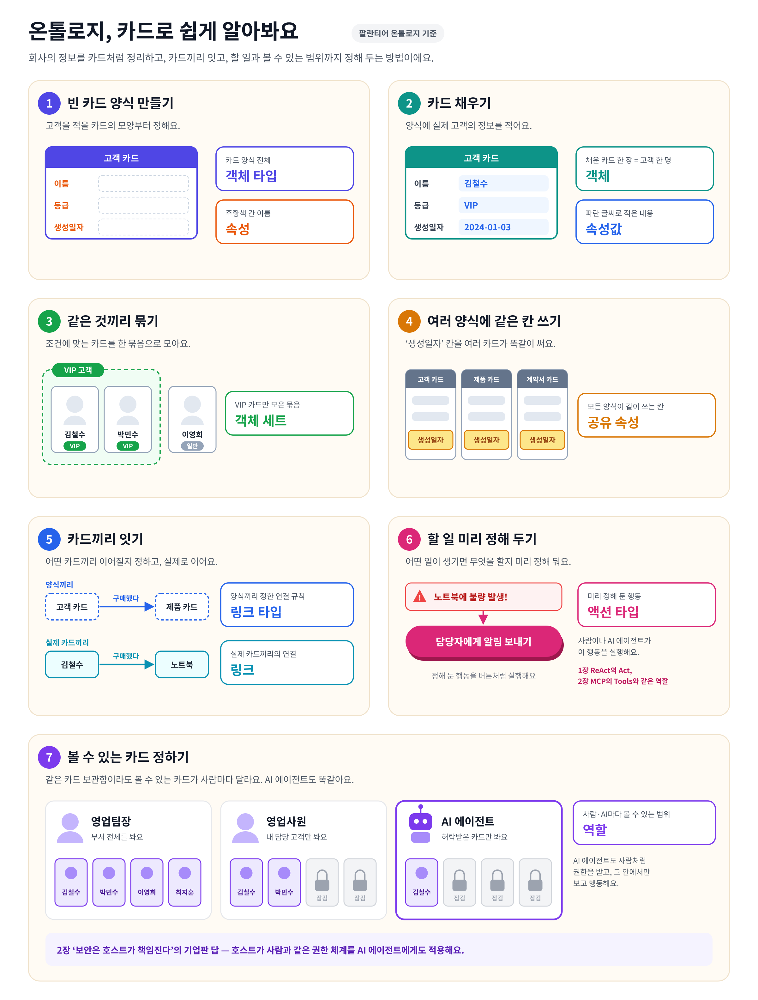

**객체 타입 / 객체 / 객체 세트**

**객체 타입** : 테이블의 스키마

- 예: 고객 시트 그 자체. "고객이란 이름, 등급, 생성일자를 가진 것"이라는 틀

---

**객체** : 테이블의 한 행

- 예: 고객A, 제품B 같은 실제 인스턴스

**객체 세트** : 여러 객체의 모음

- 예: VIP 고객 전체

---

**속성 / 속성값**

**속성** : 테이블의 열. 즉, 객체가 가진 특징

- 예: 이름, 날짜, 금액

**속성값** : `김철수`, `2024-01-03` 같이 특정 객체가 가지는 속성의 실제 값

---

**공유 속성**

: 여러 객체 타입에서 공통으로 쓰는 속성

- 예: "생성일자" 속성을 고객, 제품, 계약서 모두에서 일관되게 관리할 수 있음

---

**링크 타입 / 링크**

**링크 타입** : 관계의 스키마

- 예: "구매했다", "담당한다"

**링크** : 실제 관계의 인스턴스

- 예: "고객A가 제품B를 구매했다"

---

**액션 타입** : 일반 DB와의 가장 큰 차이점!

- 데이터를 읽는 것을 넘어, **실제 변경과 행동까지 온톨로지 위에서 정의**하는 것
    - 예: "불량 발생 시 담당자에게 알림 발송" 같은 행동이 온톨로지의 일부가 될 수 있다
    - **1장의 ReAct와 2장의 MCT Tools와의 연결지점**
        
        액션 타입은 1장 ReAct의 **Act(행동)**, 2장 MCP의 **Tools**와 같은 역할

        에이전트가 온톨로지를 보고 판단한 뒤, 미리 정의된 액션 타입을 도구처럼 호출해 실제 행동을 수행        

---

**역할 (Roles)**

- 직급, 부서, 지역에 따라 접근 권한을 객체 단위까지 세밀하게 제어할 수 있음
- **AI 에이전트도 사람처럼 권한을 부여받음** -> 부여받은 범위 안의 데이터만 조회·실행 가능

#### **세 가지 데이터 구조 비교**

| 관계형 DB (테이블) | 그래프 DB | 팔란티어 온톨로지 |
| --- | --- | --- |
| 테이블 스키마 | - | 객체 타입 |
| 행 (Row) | 노드 | 객체 |
| 열 (Column) | - | 속성 |
| 필드 값 | - | 속성값 |
| 조인 (Join) | 엣지 | 링크 타입 |
| - | - | **액션 타입** ← 온톨로지만의 차별점! |

### **3-3. 실전에서는 어떻게 쓰이나**

#### **그래프 - 기업/산업 스케일**

- **그래프 DB (Neo4j) 사용 기업 사례**
    
    포춘 100대 기업 중 84개사, 포춘 500대 기업의 58%가 Neo4j를 사용하고 있으며, Uber, Walmart, Klarna 등에서는 에이전틱 AI 배포에 활용하고 있습니다.
    
    - 사례: 그래프 구조는 사기 탐지, 추천 엔진, 소셜 네트워크 관계 분석에서 활발히 사용되며, Facebook·LinkedIn 같은 소셜 플랫폼들은 그래프 DB 위에 구축된 대표 사례.

- 그래프 지식 베이스 + 실패 로그를 통한 강화학습 : **사내 챗봇 & 에이전트 구축**
    
    - 사례: Uber는 LangGraph 기반의 모듈형 그래프 에이전트 시스템을 구축했고, 내부 챗봇 빌더와 Picasso라는 워크플로우 플랫폼을 통해, 조직의 지식과 통합된 대화형 에이전트를 운영.
        
        또한, 에이전트 아키텍처를 깊이 몰라도 Uber 보안팀 같은 다른 팀이 규칙을 추가할 수 있는 구조!
        
        Uber의 Genie: Uber’s Gen AI On-Call Copilot라는 내부 시스템은 도메인 팀이 엔지니어링 위키, PDF, Google Docs 등 거의 모든 사내 지식 소스와 통합된 LLM 기반 Slack 봇을 간편히 배포할 수 있게 해줌!

#### **그래프 - 개인/팀 프로젝트 스케일**

- **LightRAG (홍콩대 HKUDS, EMNLP 2025)**

    GraphRAG의 장점(그래프 기반 검색)은 살리면서, 인덱싱 비용을 줄인 가벼운 그래프 RAG

    - 논문: EMNLP 2025 게재
    - 오픈소스: GitHub - HKUDS/LightRAG
    - 바로 띄워 쓸 수 있는 **LightRAG Server**도 제공

    - LightRAG가 GraphRAG보다 비용이 낮은 이유
        - 핵심: GraphRAG는 **커뮤니티 요약을 미리 만들어 두지만,** LightRAG는 이 단계를 **생략**

        |  | GraphRAG | LightRAG |
        | --- | --- | --- |
        | 사전 준비 | 커뮤니티별 요약을 LLM으로 미리 생성 | 커뮤니티 요약 없음 |
        | 검색 방식 | 커뮤니티 요약 + 그래프 활용 | Low-level / High-level 키로 검색 후, 결과와 원본 청크를 함께 주입 |
        | 비용 | 커뮤니티 수만큼 LLM 추가 호출 | LLM 호출이 적어 비용이 낮아질 수 있음 |

#### **graphify**

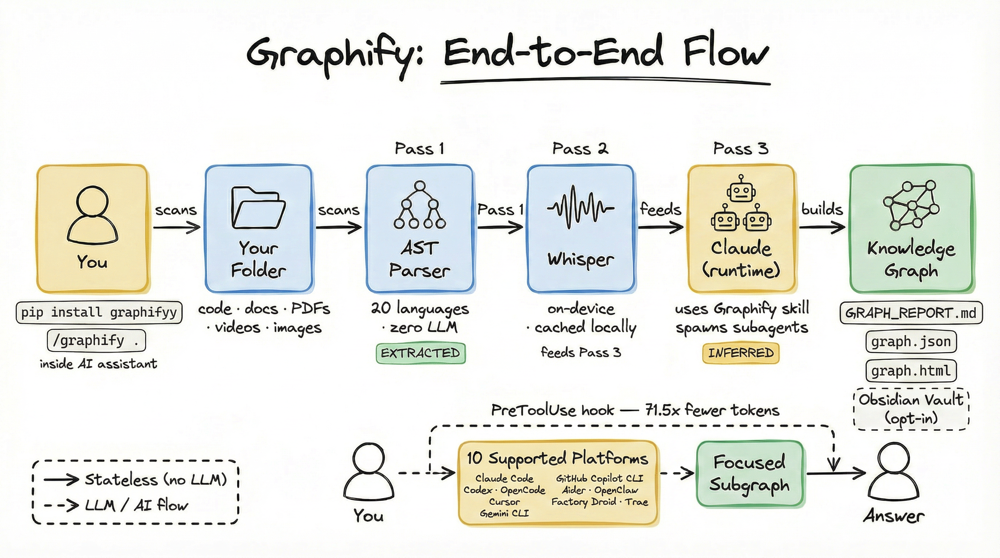](attachment:image-3.png)

폴더 안에 있는 코드, 문서, PDF 등을 읽어서 **"무엇이 무엇과 어떻게 연결되는지"를 그래프로 만들어 주는 오픈소스 도구**. Claude Code, Codex, OpenCode, OpenClaw, Cursor 같은 AI 코딩 도우미에 기능(스킬)으로 설치해서 쓰며, 도우미 안에서 `/graphify .` 명령 하나로 실행 가능.

**차이점**

- **claude-obsidian** : 클로드 코드 사용을 통해 지식을 축적
- **graphify** : 기존 파일/코드를 그래프로 변환

## **온톨로지 - 팔란티어 공식 문서의 온톨로지 적용 사례**

**상황:** 의료 기기 제조사를 상상해 봅시다! 이 회사는 동시에 여러 복잡한 것들을 관리해야 하는 상황

- 수십 개의 공급업체와의 납품 일정
- 여러 공장의 생산 라인 상태
- 전 세계 창고의 입출고 현황
- 고객사별 납품 계약과 수명 주기

이 데이터들이 ERP, MES, CRM, 물류 시스템 등 **수백 개의 시스템에 흩어져** 있는 상태

**팔란티어는 이 수백 개의 데이터 소스를 하나의 온톨로지로 통합했다**

```
[제조 공장] ──생산──> [작업 지시서] ──출하──> [고객]
      │                    │
      └── [기계 장비]    [입고 패키지]
                              │
                         [출고 화물]
```

- 이제 "이 납품이 왜 지연됐나?" 한 번의 질문으로,
    
    공장 → 작업지시서 → 물류 → 고객까지의 **관계를 통해 추론**할 수 있어서, 각각의 시스템을 따로따로 찾아볼 필요가 없어졌다!


## **4. XAI**

### **Intro. 기존 AI 모델이 답하지 못하는 문제**

**"왜 그 결정을 내렸는가!"**

예를 들어, 정확도 99%짜리 피부암 진단 AI가 있다고 가정해보자.

연구자들이 AI가 왜 특정 사진을 암으로 판정하는지 들여다봤더니, **사진 속에 반창고가 붙어 있으면 암으로 분류**하는 경향이 있었다.

반창고가 붙은 피부 사진은 대부분 이미 의사가 살펴본 병변 사진이었기 때문에, AI가 반창고 자체를 암의 신호로 학습해버린 것이다.

=> 이는 입력(사진)과 출력(암/정상)만 보면 절대 발견할 수 없는 문제!

=> **그래서 등장하게 된 것이 설명 가능한 인공지능(Explainable AI, XAI)**

### **4-1. 블랙박스가 왜 문제인가**

딥러닝 모델은 수백만 ~ 수십억 개의 숫자(파라미터)가 복잡하게 얽혀 있어, 사람이 직접 읽을 수 없다. 입력을 넣으면 출력이 나오지만 그 사이 과정은 사실상 **블랙박스!**

| 분야 | 규제 내용 |
| --- | --- |
| 🏥 의료 | FDA는 진단 AI에 결론뿐 아니라 **근거**를 요구한다. 설명 없이는 인허가 자체가 안 된다. |
| 💳 금융 | EU AI Act는 대출·보험·채용 AI가 불리한 결정을 내렸을 때 **고객에게 이유를 설명**할 법적 의무를 부과했다.

현업에서도 Tree 계열 앙상블은 활발하게 쓰이나 딥러닝 계열은 아직 설명력이 더 필요한 단계.  |
| 🚗 자율주행 | 사고 발생 시 왜 그 판단을 했는지 재현 및 설명이 가능해야 책임 소재를 따질 수 있다. |

이게 단순히 "알면 더 좋은" 수준의 문제가 아닌 이유는 **규제** 때문!

### **4-2. 기존 해결 시도들**

#### **1. 회귀 분석 (Regression) : 완전한 화이트박스**

- 가장 고전적인 방법
- 결과 = a × 나이 + b × 소득 + c × 신용점수 + … 처럼 계수를 직접 읽을 수 있음.

- “나이가 1 늘면 대출 거절 확률이 2% 오른다” → 완벽한 설명!
 
- **한계:** 세상은 그렇게 단순하지 않다. 이미지, 텍스트, 복잡한 패턴에서는 선형 모델로 충분한 정확도를 낼 수 없음. 설명은 완벽한데 성능이 너무 낮음.

#### **2. SHAP / LIME : 사후적 설명 (Post-hoc Explanation)**

- 딥러닝 모델은 그대로 놔두고, 외부에서 “어떤 입력 특성이 이 결과에 얼마나 기여했는지”를 근사 계산해서 보여주는 방법
- 예를 들어 대출 거절 결과에 대해 SHAP을 쓰면 이런 출력이 나온다:
    
    `거절 이유 기여도:
      - 연체 이력:   +34%  (거절 방향)
      - 소득 수준:   -18%  (승인 방향)
      - 부채 비율:   +27%  (거절 방향)`
    
- **한계:** 모델이 실제로 하는 연산을 설명하는 게 아sls, 입력을 조금씩 바꿔보며 **역으로 추정**하는 방법. “진짜 이유”가 아니라 “그렇게 보이는 것”일 수 있음. 즉, 모델이 실제로 연체 이력을 보고 결정한 건지, 아니면 연체 이력과 연관된 다른 무언가(예: 우편번호)를 보고 결정한 건지 알 수 없음.

- **SHAP 알고리즘 (SHaply Additive exPlanations)**

    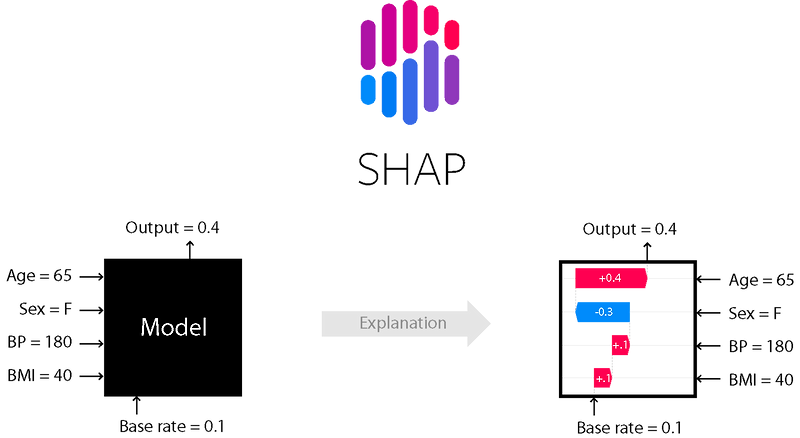

    - **게임 이론의 Shapley Value 개념을 ML 모델 해석에 적용**
    - 각 feature가 예측값에 기여한 정도를 수치화하여 설명

    - **알고리즘 작동방식**
        1. **기준값 설정**: 전체 데이터셋의 평균 예측값을 기준으로 삼음
        2. **Feature 조합 생성**: 각 feature를 포함/제외한 모든 가능한 조합을 고려
        3. **기여도 계산**: 각 feature가 있을 때와 없을 때의 예측값 차이를 계산
        4. **Shapley Value 산출**: 모든 조합에서의 기여도를 공정하게 평균하여 최종 기여도 결정
        5. **시각화**: 각 feature의 SHAP value를 통해 예측에 미친 영향을 직관적으로 표현     

        - **핵심 개념**
            - SHAP value = 해당 feature가 예측값을 기준값에서 얼마나 이동시켰는가
            - 양수: 예측값을 높이는 방향으로 기여
            - 음수: 예측값을 낮추는 방향으로 기여   

        - **장점**  
            - 이론적으로 탄탄한 근거 (게임 이론의 Shapley Value 기반)
            - 모든 feature의 기여도 합 = 실제 예측값 - 기준값 (수학적 일관성)
            - 개별 예측뿐만 아니라 전체 모델의 feature 중요도도 파악 가능
            - 다양한 시각화 도구 제공 (Force Plot, Summary Plot, Dependence Plot 등)

        - **단점**    
            - 모든 feature 조합을 고려하므로 계산 비용이 높음 (feature 수가 많을 때 느림)
            - LIME보다 상대적으로 복잡하고 이해하기 어려울 수 있음
            - 근사 알고리즘을 사용할 경우 정확도와 속도 사이의 트레이드오프 존재

- **LIME 알고리즘 (Local Interpretable Model-Agnostic Explanations**

    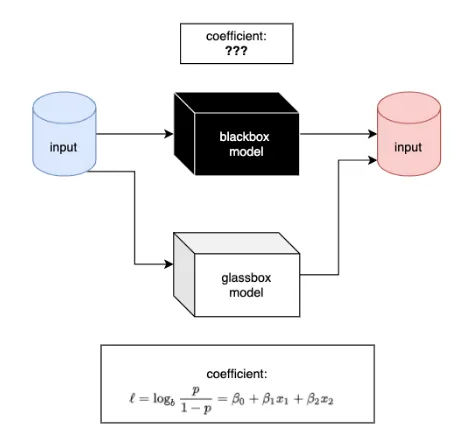

    - **Local:** 전체적인 모델이 아닌 샘플 하나 분석. 매우 local해지므로 **선형 회귀 모델**을 적용할 수 있음.
    - **Interpretable Explanation:** 입력과 결과에 대해 이해 가능한 설명이 제공되어야함.
    - **Model-agnostic:** 어떤 블랙박스 모델을 사용하든지 간에 무관하게 사용할 수 있음

    - **알고리즘 작동 방식**

        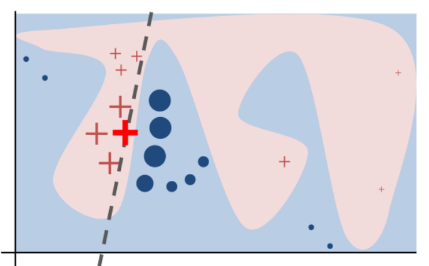

        1. **입력 데이터 (red cross) 선택**
        2. **지역탐색을 위해 주변의 값 무작위 샘플링**
            - 입력 데이터를 약간씩 **변형**하여 여러 샘플을 생성
            - ex) 텍스트: 단어를 랜덤하게 제거, 이미지: 일부 픽셀 블러 처리 등
        3. **해당 샘플에 대해 블랙박스 모델로 예측**
        4. **간단한 해석 가능한 모델 학습 (예: 선형 모델)**
            - 위 샘플과 예측값, 가중치를 이용해 해석 가능한 간단한 모델 학습
        5. **결과 해석**
            - 선형 모델의 계수를 해석해서 어떤 feature가 예측에 영향을 주었는지 파악

    - **장점**
        - 분류에 사용한 블랙박스 모델이 무엇이든 적용 가능
        - 딥 러닝이나 GPU 등을 사용하지 않고도 적용할 수 있는, 가벼운 XAI 기법
        - 모델 내부 변수보다 이해하기 쉬움

    - **단점**
        - 슈퍼 픽셀을 구하는 알고리즘과 모델 *g*의 결정 경계를 확정 짓는 방식이 비결정적(non-deterministic). -> 샘플링 위치에 따라 랜덤한 모델 결과 도출
        - LIME은 데이터 하나에 대한 설명이기 때문에 모델 전체에 대한 일관성 보전 불가    

#### **3. LLM + RAG : 블랙박스로 블랙박스 설명하기**

- “이유를 GPT한테 물어보자”는 접근
- 모델의 출력과 입력 데이터를 GPT에게 넘기고 "왜 이런 결정을 내렸을까요?"라고 묻는 방식
- **한계:** GPT 자체도 블랙박스이므로, **블랙박스가 블랙박스를 설명하는 셈**. GPT가 그럴듯한 설명을 생성해줄 수는 있지만, 그게 딥러닝 모델의 실제 내부 연산과 일치한다는 보장이 없음.

#### **세 방법 비교 요약**

| 방법 | 설명 가능성 | 성능 | 신뢰도 |
| --- | --- | --- | --- |
| 회귀 분석 | ✅ 완전한 화이트박스 | ❌ 낮음 | ✅ 높음 |
| SHAP / LIME | 🔶 근사 설명 | ✅ 모델 성능 유지 | 🔶 부분적 |
| LLM + RAG | 🔶 생성된 설명 | ✅ 모델 성능 유지 | ❌ 낮음 |

### **4-3. Mechanistic Interpretability (기계적 해석 가능성)**

**출발점** : "블랙박스 자체를 열어버리면 어떨까?"

=> **모델이 무엇을 출력하는가가 아니라, 모델이 어떻게 그 답에 도달하는 가를 이해하자.**

딥러닝 모델의 내부, 즉 가중치, 뉴런, 어텐션 헤드를 직접 분석해서, 특정 기능이 모델 안 어디에 어떻게 구현되어 있는지 **회로(circuit) 수준까지 역공학(reverse engineering)** 하는 연구 분야!

#### **일반 XAI vs Mechanistic Interpretability**

|  | 일반 XAI (SHAP, LIME 등) | Mechanistic Interpretability |
| --- | --- | --- |
| 접근 방식 | 외부에서 관찰 | 내부를 직접 해부 |
| 핵심 질문 | "이 입력이 결과에 중요했나?" | "이 뉴런이 어떤 연산을 수행하나?" |
| 분석 수준 | 입력-출력 관계 | 가중치·회로 수준 |
| 성격 | 사후적(post-hoc) | 구조적(mechanistic) |
| 비유 | 외부에서 집 창문으로 들여다보기 | 집 구조도를 직접 그리기 |

#### **핵심 기법 : Activation Patching (활성값 패칭)**

: **모델 내부의 어느 위치가 답을 결정하는지**를 찾는 방법

**1. 입력 두 개를 준비**

|  | 입력 | 모델의 답 |
| --- | --- | --- |
| A (기준) | "프랑스의 수도는" | 파리 |
| B (비교) | "독일의 수도는" | 베를린 |

**2. B를 처리하는 도중, 특정 위치의 값을 A의 값으로 바꿔 끼움**

```
입력 B 처리 중  ──▶  [레이어 1] ──▶ [레이어 2] ──▶ [레이어 3] ──▶  출력
                                        ▲
                         입력 A를 처리할 때 나온 활성값으로 교체
```

**3. 출력이 어떻게 바뀌는지 관찰**

- 출력이 "베를린" → "파리"로 바뀌면 -> 그 위치가 **"어느 나라에 대한 질문인지"를 답까지 전달하는 핵심 경로**
- 출력이 **바뀌지 않으면** -> 그 위치 **하나만으로는** 답을 결정하지 않음.

**=> 마치 고장 원인을 찾을 때 정상 기기의 부품을 하나씩 바꿔 끼워 보며 어떤 부품이 결과를 좌우하는지 찾아내는 것과 같습니다!**

### **4-4. 핵심 개념 3가지**

#### **1. 모델 안에는 무엇이 있는가? : Features (특징)**

**Feature란?**

: 모델이 입력에서 알아챈 **개념**. 특정 단어일 수도 있고, 언어·말투·상황처럼 더 추상적인 것일 수도 있음.

**Feature는 어디에 저장될까?**

| 저장 위치 | 설명 | 비유 |
| --- | --- | --- |
| 개별 뉴런 | 개념 하나가 뉴런 하나에 담김 | 빨강 = R 다이얼 하나 |
| 방향 벡터 | 개념 하나가 여러 뉴런의 조합에 담김 | 주황 = R 많이 + G 조금 |

=> 입력에 그 개념이 등장하면 해당 뉴런(또는 뉴런 조합)이 **켜짐.** (활성값이 커짐)

**하지만 현실은** : 뉴런 하나에 개념 하나가 깔끔하게 담기는 경우는 드물다. 오히려 **뉴런 하나에 서로 관계없는 여러 개념이 섞여 있는 경우**가 많다.

#### **2. 그것들이 어떻게 연결되어 일하는가? : Circuits (회로)**

**Circuit(회로)란?**

: 개별 뉴런을 넘어, **여러 뉴런 / 어텐션 헤드가 연결되어 특정 기능을 수행하는 서브 네트워크**

이 회로를 발견할 경우 : "이 기능을 제거하고 싶다" 등의 조작이 이론적으로 가능해짐!

#### **3. 그런데 왜 해석하기 어렵나? : Superposition (중첩)**

표현해야 할 개념은 수백만, 수십억 개인데 뉴런 수가 훨씬 적다면??

=> **하나의 뉴런이 여러 개념을 중첩(superposition)해서 저장한다.**

1. 모델은 개념(특징)을 뉴런 하나가 아니라 **활성 공간 안의 방향**으로 표현함. 
2. 만약 공간이 2차원이면 서로 전혀 겹치지 않는 (직교하는) 방향은 2개 밖에 없음. 특징이 2개면 깔끔하게 하나씩 배정할 수 있다.
3. 그런데 표현해야 할 특징이 5개라면, 모델은 5개 방향을 **조금씩 겹치게 배치**함.
4. 겹치니까 한 특징을 읽을 때 다른 특징이 조금 섞여 들어오는데, 이를 **간섭(interference)**이라고 함.
5. 모델이 간섭을 감수하는 이유는 **특징이 드물게(sparse) 나타나기** 때문. 5개가 동시에 켜지는 일은 거의 없어서, 대부분의 경우 간섭이 문제를 일으키지 않음. 그래서 손해보다 더 많은 특징을 담는 이득이 크다.
6. 그리고 이 특징 방향들이 뉴런 축(좌표축)과 맞지 않으니, **뉴런 하나를 보면 여러 특징이 조금씩 걸쳐 보이게 된다.**
=> 앞에서 말한 다의성이 생기는 이유!

이게 Mech. Int. 연구를 어렵게 만드는 가장 큰 원인! "뉴런 하나 = 개념 하나"가 아니기 때문에, 뉴런을 읽어도 무슨 개념인지 바로 알 수 없다!

이를 해결하려고 나온 도구가 **Sparse Autoencoder(SAE)**. **중첩된 개념들을 수학적으로 분리해서 각 개념을 독립적으로 추출하는 방법.**

### **4-5. 왜 지금 중요한가**

#### **AI 안전(AI Safety)과의 연결**

AI 모델이 실제로 어떤 내부 목표를 가지고 연산하는지, 즉 우리가 원하는 대로 작동하는지, 아니면 우리가 모르는 방향으로 최적화하고 있는지 알아낼 수 있는 수단.

모델이 커질수록, 그리고 더 많은 의사결정을 위임할수록, 내부를 이해하는 일이 더 중요해짐!

#### **현재 투자 현황**

Mechanistic Interpretability 분야에 집중 투자하고 있는 주요 기관들:

- **Anthropic** — Claude를 만드는 회사. Interpretability 팀이 별도로 있고, 회사의 핵심 연구 과제 중 하나
- **DeepMind** — Google의 AI 연구소
- **Redwood Research** — AI 안전 전문 연구기관

아직 초기 연구 단계고, 대형 모델 전체를 이해하기까지는 갈 길이 멀다. 하지만 방향 자체는 **‘블랙박스를 외부에서 추정하는 것’**에서 **‘블랙박스를 직접 여는 것’**으로 바뀌고 있다!

**즉, XAI는 "AI 설명을 어떻게 만들까"에서 시작해서, "AI 내부를 어떻게 이해할까"로 진화하고 있다. Mechanistic Interpretability는 그 최전선이고, AI가 커질수록 더 중요해지는 분야라고 볼 수 있다!!**

